# Módulo 09: Visualización de datos, parte 1

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m09-visualizacion-1.ipynb](m09-visualizacion-1.ipynb). No es una tarea entregada del programa.

Una tabla con cientos de filas no deja ver la forma de los datos; un gráfico, sí. En esta lección usamos **matplotlib**, la librería base de visualización en Python, para responder preguntas concretas sobre los pasajeros del Titanic (`titanic.csv`): cómo se distribuyen las edades, qué valores son atípicos y cómo se reparten los pasajeros entre grupos.

1. Anatomía de una figura
2. Revisar los datos antes de graficar
3. Histogramas y elección de bins
4. Cómo leer un diagrama de caja
5. Conteos y gráficos de barras
6. Títulos, etiquetas y ticks
7. Guardar figuras con `savefig`
8. Redactar una interpretación
9. Errores frecuentes
10. Ejercicio

## 1. Anatomía de una figura

Un gráfico de matplotlib tiene dos niveles. La **figura** (`Figure`) es el lienzo completo; los **ejes** (`Axes`) son cada panel con sus coordenadas, donde se dibujan los datos. Una figura puede contener varios ejes.

Hay dos estilos de uso:

| Estilo | Ejemplo | Cuándo conviene |
| --- | --- | --- |
| pyplot (estado implícito) | `plt.hist(x)`, `plt.title(...)` | Gráficos rápidos de un solo panel |
| Orientado a objetos | `fig, ax = plt.subplots()`, `ax.hist(x)`, `ax.set_title(...)` | Varios paneles, control fino y código reutilizable |

En el estilo pyplot, cada llamada actúa sobre "los ejes actuales", que matplotlib elige por nosotros. En el orientado a objetos se indica explícitamente sobre qué ejes se dibuja. En esta lección usamos el segundo.

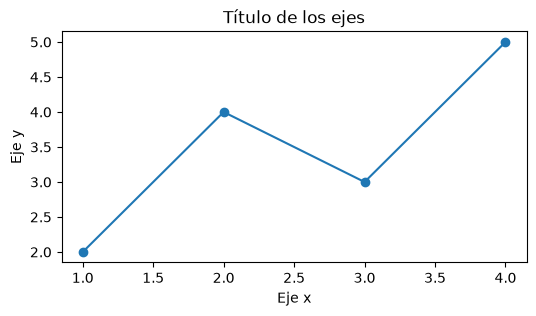

Figure Axes


In [1]:
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([1, 2, 3, 4], [2, 4, 3, 5], marker="o")
ax.set_title("Título de los ejes")
ax.set_xlabel("Eje x")
ax.set_ylabel("Eje y")
plt.show()

print(type(fig).__name__, type(ax).__name__)

## 2. Revisar los datos antes de graficar

Antes de dibujar conviene saber cuántas filas hay, de qué tipo es cada columna y si faltan valores. Algunas funciones de matplotlib ignoran los `NaN` en silencio y otras producen gráficos vacíos (se ve en la sección de errores frecuentes), así que es mejor comprobarlo primero.

In [2]:
titanic = pd.read_csv("titanic.csv")
print(titanic.shape)
print(titanic.dtypes)
print("\nValores faltantes por columna:")
print(titanic.isna().sum())

(887, 8)
Survived                     int64
Pclass                       int64
Name                        object
Sex                         object
Age                        float64
Siblings/Spouses Aboard      int64
Parents/Children Aboard      int64
Fare                       float64
dtype: object

Valores faltantes por columna:
Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64


En esta versión del archivo no falta ninguna edad, pero no siempre es así. Cuando una columna tiene faltantes, lo habitual es graficar `serie.dropna()` e indicar en el texto cuántas filas se excluyeron.

In [3]:
edad = titanic["Age"].dropna()
print(f"Edades disponibles: {len(edad)} de {len(titanic)}")
print(edad.describe().round(2))

Edades disponibles: 887 de 887
count    887.00
mean      29.47
std       14.12
min        0.42
25%       20.25
50%       28.00
75%       38.00
max       80.00
Name: Age, dtype: float64


## 3. Histogramas y elección de bins

Un **histograma** divide el rango de una variable numérica en intervalos (**bins**) y dibuja una barra por intervalo, con altura igual al número de observaciones que caen en él. Muestra la forma de la distribución: dónde se concentran los datos, si es simétrica o tiene cola hacia un lado.

El número de bins cambia lo que se ve. Con pocos, la forma se aplana; con demasiados, aparece ruido. Una referencia clásica es la regla de Sturges, para $n$ observaciones:

$$k = \lceil \log_2 n \rceil + 1$$

matplotlib también acepta `bins="auto"`, que elige el ancho a partir de los datos.

Bins según Sturges: 11


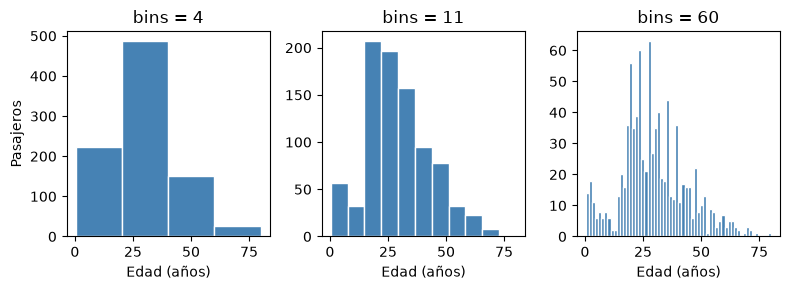

In [4]:
k_sturges = int(np.ceil(np.log2(len(edad))) + 1)
print("Bins según Sturges:", k_sturges)

fig, axes = plt.subplots(1, 3, figsize=(8, 3), sharey=False)
for ax, bins in zip(axes, [4, k_sturges, 60]):
    ax.hist(edad, bins=bins, color="steelblue", edgecolor="white")
    ax.set_title(f"bins = {bins}")
    ax.set_xlabel("Edad (años)")
axes[0].set_ylabel("Pasajeros")
fig.tight_layout()
plt.show()

Con 4 bins solo se ve que la mayoría de los pasajeros tenía entre 20 y 40 años. Con 11 aparece la forma: un pico entre los 20 y los 30 años, un grupo de niños pequeños y una cola larga hacia la derecha. Con 60, las barras suben y bajan de un intervalo al siguiente (muchas edades están redondeadas) sin cambiar la idea general: el detalle extra es ruido.

## 4. Cómo leer un diagrama de caja

El **diagrama de caja** (boxplot) resume una distribución con cinco valores y señala los atípicos:

| Elemento | Qué representa |
| --- | --- |
| Línea dentro de la caja | Mediana (percentil 50) |
| Bordes de la caja | Primer cuartil $Q_1$ (percentil 25) y tercer cuartil $Q_3$ (percentil 75) |
| Altura de la caja | Rango intercuartílico, $IQR = Q_3 - Q_1$: el 50 % central de los datos |
| Bigotes | Llegan hasta el dato más extremo que no se aleja más de $1.5 \cdot IQR$ de la caja |
| Puntos sueltos | Valores atípicos: fuera de $[Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR]$ |

Los bigotes no terminan en los límites $Q_1 - 1.5 \cdot IQR$ y $Q_3 + 1.5 \cdot IQR$, sino en el último dato real dentro de ellos.

In [5]:
q1, q3 = edad.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = edad[(edad < lim_inf) | (edad > lim_sup)]

print(f"Q1 = {q1:.2f}, mediana = {edad.median():.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Límites: [{lim_inf:.2f}, {lim_sup:.2f}]")
print(f"Bigote superior: {edad[edad <= lim_sup].max()}; bigote inferior: {edad[edad >= lim_inf].min()}")
print(f"Atípicos: {len(atipicos)} pasajeros, de {atipicos.min()} a {atipicos.max()} años")

Q1 = 20.25, mediana = 28.00, Q3 = 38.00, IQR = 17.75
Límites: [-6.38, 64.62]
Bigote superior: 64.0; bigote inferior: 0.42
Atípicos: 13 pasajeros, de 65.0 a 80.0 años


El límite inferior es negativo, así que no hay atípicos por abajo y el bigote inferior llega a la edad mínima. Los diagramas de caja son especialmente útiles para **comparar grupos** lado a lado:

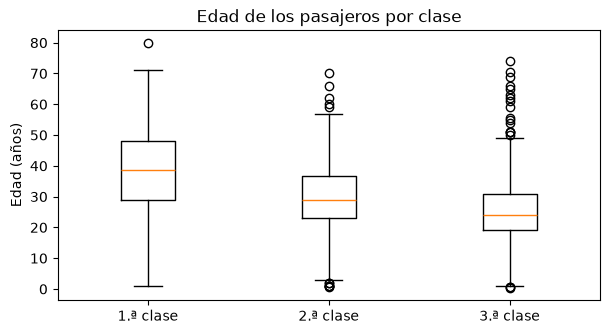

Pclass
1    38.5
2    29.0
3    24.0
Name: Age, dtype: float64


In [6]:
grupos = [titanic.loc[titanic["Pclass"] == c, "Age"] for c in (1, 2, 3)]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot(grupos, tick_labels=["1.ª clase", "2.ª clase", "3.ª clase"])
ax.set_title("Edad de los pasajeros por clase")
ax.set_ylabel("Edad (años)")
plt.show()

print(titanic.groupby("Pclass")["Age"].median())

## 5. Conteos y gráficos de barras

Para una variable **categórica** (clase, sexo, puerto) no se usa un histograma sino un **gráfico de barras**: una barra por categoría. El primer paso es contar con `value_counts()`, que ordena de la categoría más frecuente a la menos frecuente. Si las categorías tienen un orden natural, como las clases 1, 2 y 3, conviene reordenarlas con `sort_index()`.

In [7]:
print(titanic["Pclass"].value_counts())               # ordenado por frecuencia
print(titanic["Pclass"].value_counts().sort_index())  # ordenado por clase

Pclass
3    487
1    216
2    184
Name: count, dtype: int64
Pclass
1    216
2    184
3    487
Name: count, dtype: int64


Las barras también sirven para comparar una proporción entre grupos. La media de una columna 0/1, como `Survived`, es la proporción de unos:

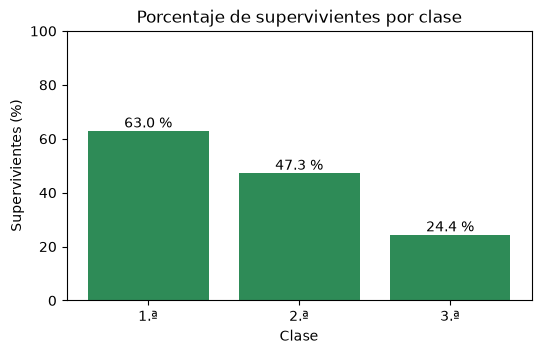

In [8]:
supervivencia = titanic.groupby("Pclass")["Survived"].mean() * 100

fig, ax = plt.subplots(figsize=(6, 3.5))
barras = ax.bar(["1.ª", "2.ª", "3.ª"], supervivencia, color="seagreen")
ax.bar_label(barras, fmt="%.1f %%")    # rotula cada barra con su valor
ax.set_title("Porcentaje de supervivientes por clase")
ax.set_xlabel("Clase")
ax.set_ylabel("Supervivientes (%)")
ax.set_ylim(0, 100)
plt.show()

## 6. Títulos, etiquetas y ticks

Un gráfico debe entenderse sin leer el código. Lo mínimo es un título que diga qué se muestra, etiquetas en ambos ejes **con unidades** y marcas (**ticks**) legibles.

| Método de `ax` | Para qué sirve |
| --- | --- |
| `set_title`, `set_xlabel`, `set_ylabel` | Título y etiquetas de los ejes |
| `set_xticks(posiciones, etiquetas)` | Elegir dónde van las marcas y qué texto llevan |
| `tick_params(axis="x", rotation=45)` | Girar las etiquetas largas |
| `set_xlim`, `set_ylim` | Fijar el rango visible |
| `grid(axis="y", alpha=0.3)` | Líneas de referencia discretas |

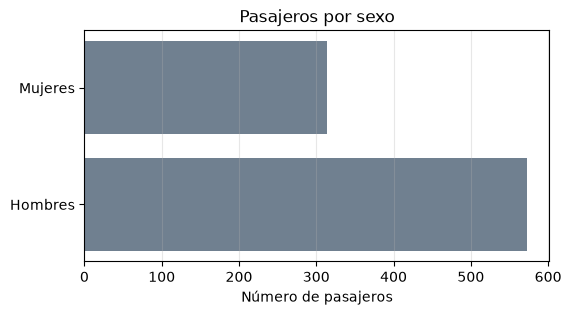

Sex
male      573
female    314
Name: count, dtype: int64


In [9]:
por_sexo = titanic["Sex"].value_counts()
etiquetas = por_sexo.index.map({"male": "Hombres", "female": "Mujeres"})

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh([0, 1], por_sexo.values, color="slategray")
ax.set_yticks([0, 1], etiquetas)   # posiciones y etiquetas
ax.set_title("Pasajeros por sexo")
ax.set_xlabel("Número de pasajeros")
ax.grid(axis="x", alpha=0.3)
plt.show()

print(por_sexo)

## 7. Guardar figuras con `savefig`

`fig.savefig(destino)` escribe la figura en un archivo. Los parámetros más útiles son:

| Parámetro | Efecto |
| --- | --- |
| `format` | `"png"`, `"jpg"`, `"pdf"`, `"svg"`…; si se omite, se deduce de la extensión del nombre |
| `dpi` | Puntos por pulgada: con `figsize=(6, 3)` y `dpi=100`, la imagen mide 600 x 300 píxeles |
| `bbox_inches="tight"` | Recorta el margen sobrante para que no se corten títulos ni etiquetas |

PNG es un formato sin pérdida, adecuado para gráficos con líneas y texto. JPG comprime con pérdida y está pensado para fotografías, aunque muchas plataformas lo piden. Para no crear archivos en esta lección, guardamos en memoria con `io.BytesIO`, que se comporta como un archivo.

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(edad, bins=k_sturges, color="steelblue", edgecolor="white")
ax.set_title("Edad de los pasajeros")

for formato, dpi in [("png", 100), ("png", 200), ("jpg", 100)]:
    buffer = io.BytesIO()
    fig.savefig(buffer, format=formato, dpi=dpi, bbox_inches="tight")
    print(f"{formato} a {dpi} dpi: {buffer.getbuffer().nbytes / 1024:.0f} KB")

# Leer el PNG de vuelta para ver su tamaño en píxeles (alto, ancho, canales)
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=100)
buffer.seek(0)
print("Píxeles a 100 dpi sin recorte:", plt.imread(buffer).shape)
plt.close(fig)    # cerrar la figura para que no se muestre

png a 100 dpi: 10 KB
png a 200 dpi: 22 KB
jpg a 100 dpi: 15 KB
Píxeles a 100 dpi sin recorte: (300, 600, 4)


En un proyecto real, el destino sería un nombre de archivo, por ejemplo `fig.savefig("edades.jpg", dpi=150, bbox_inches="tight")`.

## 8. Redactar una interpretación

Un gráfico no se explica solo. Una buena interpretación responde, en dos o tres frases, a cuatro preguntas:

1. **Qué se ve:** la forma, la tendencia o la diferencia principal.
2. **Con qué cifras:** mediana, porcentajes o rangos tomados de los datos, no a ojo.
3. **Qué significa** en el contexto del problema.
4. **Qué límites tiene:** qué no permite concluir el gráfico.

Por ejemplo, para el diagrama de caja por clase:

> La edad disminuye con la clase: la mediana es de 38.5 años en primera clase, 29 en segunda y 24 en tercera. La tercera clase concentra a los pasajeros más jóvenes, lo que encaja con un perfil de viajeros que emigraban en busca de trabajo. El gráfico describe la edad, pero no dice por sí solo si la edad influyó en la supervivencia.

Las cifras de la interpretación deben salir de una celda de código, como la mediana por clase que imprimimos en la sección 4.

## 9. Errores frecuentes

**Hacer un diagrama de caja con `NaN`.** `ax.hist` descarta los `NaN` sin avisar, pero `ax.boxplot` no: si hay un solo faltante, los cuartiles y la mediana salen como `NaN` y la caja no se dibuja. Hay que aplicar `dropna()` antes.

In [11]:
con_faltantes = pd.Series([22, 35, np.nan, 41, 28, 30])

fig, ax = plt.subplots(figsize=(6, 2.5))
resultado = ax.boxplot(con_faltantes, orientation="horizontal")
print("Mediana dibujada con NaN:", resultado["medians"][0].get_xdata())
resultado = ax.boxplot(con_faltantes.dropna(), orientation="horizontal")
print("Mediana dibujada sin NaN:", resultado["medians"][0].get_xdata())
plt.close(fig)

Mediana dibujada con NaN: [nan nan]
Mediana dibujada sin NaN: [30. 30.]


**Guardar después de mostrar.** En un notebook, `plt.show()` muestra la figura y la cierra. Un `plt.savefig()` posterior guarda una figura nueva y vacía. Hay que guardar antes de mostrar, o usar `fig.savefig()` sobre la figura concreta.

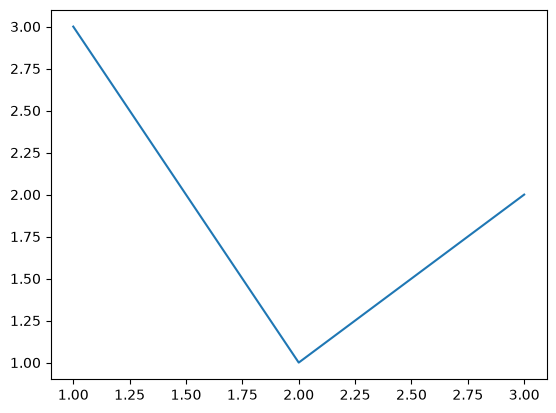

Ejes en la figura actual: 0


In [12]:
plt.plot([1, 2, 3], [3, 1, 2])
plt.show()

figura_actual = plt.gcf()          # lo que guardaría plt.savefig() ahora
print("Ejes en la figura actual:", len(figura_actual.axes))
plt.close(figura_actual)

**Usar un histograma para una categoría.** `Pclass` contiene números, pero son etiquetas de grupo. Un histograma de `Pclass` reparte los valores 1, 2 y 3 en bins arbitrarios y deja huecos sin sentido; para categorías se cuenta con `value_counts()` y se usa un gráfico de barras.

**Olvidar el orden de `value_counts()`.** Sin `sort_index()`, las barras aparecen de la más alta a la más baja (3.ª, 1.ª, 2.ª), y las etiquetas puestas a mano pueden quedar asignadas a la clase equivocada.

**Interpretar sin mirar el gráfico.** Una interpretación escrita en condicional o a partir de lo que se supone que debería aparecer no describe los datos. Debe citar lo que el gráfico y las cifras muestran.

## 10. Ejercicio

Con `titanic.csv`, analiza la tarifa pagada (`Fare`, en libras de 1912):

1. Comprueba si hay faltantes y dibuja un histograma de `Fare` con un número de bins justificado.
2. Calcula $Q_1$, $Q_3$, el IQR y cuántas tarifas son atípicas según la regla de $1.5 \cdot IQR$.
3. Dibuja un diagrama de caja de `Fare` por clase.
4. Dibuja un gráfico de barras con el número de supervivientes por sexo, con título y etiquetas.
5. Guarda el diagrama de caja como JPG en un `io.BytesIO` con `dpi=100` y `bbox_inches="tight"`, e imprime su tamaño en KB.
6. Escribe una interpretación de dos o tres frases del diagrama de caja.

### Solución

Faltantes en Fare: 0


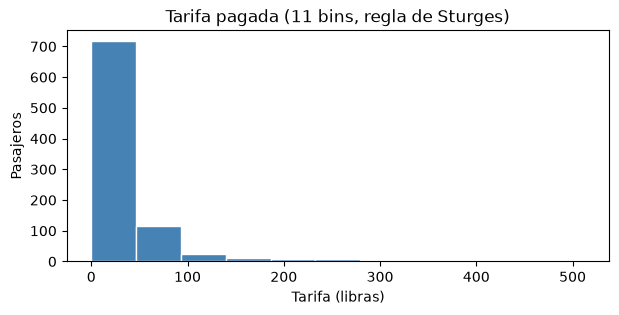

Q1 = 7.92, Q3 = 31.14, IQR = 23.21, atípicos = 116


In [13]:
tarifa = titanic["Fare"]
print("Faltantes en Fare:", tarifa.isna().sum())

bins = int(np.ceil(np.log2(len(tarifa))) + 1)    # Sturges
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(tarifa, bins=bins, color="steelblue", edgecolor="white")
ax.set_title(f"Tarifa pagada ({bins} bins, regla de Sturges)")
ax.set_xlabel("Tarifa (libras)")
ax.set_ylabel("Pasajeros")
plt.show()

q1, q3 = tarifa.quantile([0.25, 0.75])
iqr = q3 - q1
n_atipicos = ((tarifa < q1 - 1.5 * iqr) | (tarifa > q3 + 1.5 * iqr)).sum()
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}, atípicos = {n_atipicos}")

JPG en memoria: 15 KB


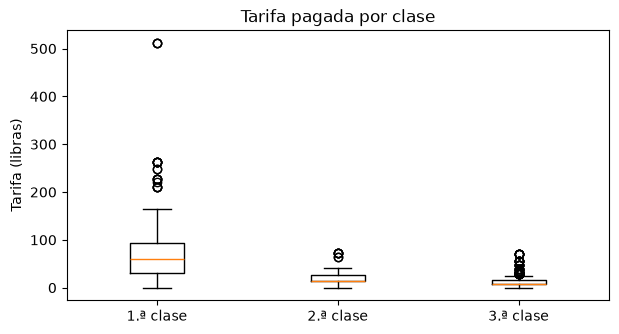

Pclass
1    60.2875
2    14.2500
3     8.0500
Name: Fare, dtype: float64
Tarifas iguales a 0: 15


In [14]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([tarifa[titanic["Pclass"] == c] for c in (1, 2, 3)],
           tick_labels=["1.ª clase", "2.ª clase", "3.ª clase"])
ax.set_title("Tarifa pagada por clase")
ax.set_ylabel("Tarifa (libras)")

buffer = io.BytesIO()
fig.savefig(buffer, format="jpg", dpi=100, bbox_inches="tight")
print(f"JPG en memoria: {buffer.getbuffer().nbytes / 1024:.0f} KB")
plt.show()

print(titanic.groupby("Pclass")["Fare"].median())
print("Tarifas iguales a 0:", (tarifa == 0).sum())

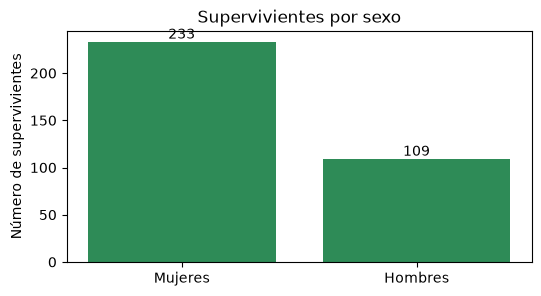

Sex
female    233
male      109
Name: count, dtype: int64


In [15]:
supervivientes = titanic.loc[titanic["Survived"] == 1, "Sex"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3))
nombres = supervivientes.index.map({"male": "Hombres", "female": "Mujeres"})
barras = ax.bar(nombres, supervivientes.values, color="seagreen")
ax.bar_label(barras)
ax.set_title("Supervivientes por sexo")
ax.set_ylabel("Número de supervivientes")
plt.show()

print(supervivientes)

**Interpretación del diagrama de caja.** La tarifa crece con la clase: la mediana es de unas 60 libras en primera, 14 en segunda y 8 en tercera. Primera clase tiene además la mayor dispersión y las tarifas más extremas, de hasta 512 libras, lo que hace que la distribución global tenga una cola larga a la derecha. Las 15 tarifas de 0 libras merecen revisión antes de usarlas en un modelo, porque pueden ser billetes de tripulación o errores de captura.

## Resumen

- Una figura (`Figure`) contiene uno o varios ejes (`Axes`); el estilo `fig, ax = plt.subplots()` da control explícito sobre cada panel.
- Antes de graficar hay que revisar faltantes: `boxplot` no tolera `NaN`.
- El histograma muestra la forma de una variable numérica, y el número de bins cambia lo que se ve.
- El diagrama de caja resume mediana, cuartiles e IQR, y marca como atípicos los valores a más de $1.5 \cdot IQR$ de la caja.
- Las categorías se cuentan con `value_counts()` y se muestran en barras; `savefig` (con `format`, `dpi` y `bbox_inches`) guarda la figura **antes** de mostrarla.

En el **Módulo 10** se trabaja con datos más desordenados: formatos largo y ancho, limpieza, correlaciones y gráficos con seaborn.